# Data Plotting Workflow

As discussed in the [previous notebook](10_Solvent_IRC_Plots.ipynb), we now have **two data files** with the gas phase and solvent IRC calculation data. They were written by *Python* straight from the IRC log files and are kept in the `data/` folder of this book.

| Files    |  Description    |
|  :---------------------------    | :-------------------------  |
| `data/SN2_IRC_Solvent_Data.txt`        | The solvent phase (Water PCM model) IRC calculation
| `data/SN2_IRC_Data_GasPhase_Data.txt`  | The gas phase calculation

We can now make some **comparisons**.

## Load Your Tools
Load in the modules needed for this exercise.

In [1]:
# ===== SETTINGS =========================================================
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("data")      # the processed IRC tables and the plot style live here
# ========================================================================

## Importing Stored Data
No need to use the raw data and process the files. We have **stored** that work as text files and **documented** the process that we used to clean and process the data. Now we can load them in and use them.

In [2]:
solvent_file = DATA / "SN2_IRC_Solvent_Data.txt"
gas_phase_file = DATA / "SN2_IRC_Data_GasPhase_Data.txt"

solvent = pd.read_csv(solvent_file, index_col=0)
gasphase = pd.read_csv(gas_phase_file, index_col=0)

print("Solvent IRC Data")
display(solvent.head())
print("\nGas Phase IRC Data")    # the '\n' is a 'new line' character
display(gasphase.head())

Solvent IRC Data


,stride,energy,E(kJ/mole),C-Cl1,C-Cl2
0,-4.91506,-955.705799,-23.171099,1.958491,3.111259
1,-4.77199,-955.705798,-23.167161,1.959315,3.097850
2,-4.48050,-955.705773,-23.100736,1.961491,3.062317
3,-4.18687,-955.705713,-22.943994,1.963740,3.026518
4,-3.88869,-955.705610,-22.673567,1.966013,2.990090



Gas Phase IRC Data


,stride,energy,E(kJ/mole),C-Cl1,C-Cl2
0,-2.08885,-955.610455,-3.714955,2.095466,2.734344
1,-2.08792,-955.610455,-3.714955,2.095449,2.734359
2,-2.08594,-955.610455,-3.714955,2.095423,2.734369
3,-1.79283,-955.610390,-3.544297,2.112965,2.689099
4,-1.49766,-955.610218,-3.092711,2.147086,2.637748


## Plots
First we must **decide** what to plot. The stride value should be similar for each since it is the same bonds in both cases that are changing (stride is a composite value that encompasses the totality of bond changes). How do the energies **compare** in gas phase vs. water as bonds break and form across the transition state? Let us plot the **relative energy** vs. **stride**.

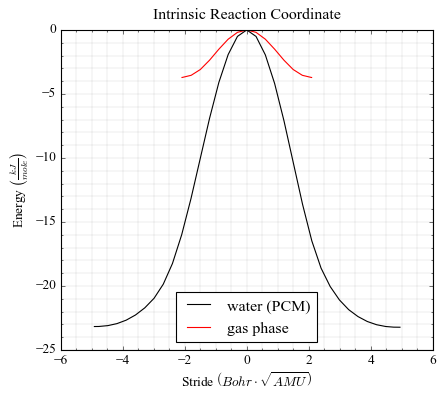

In [3]:
#| label: fig-irc-energy
#| caption: The IRC expressed as a plot of relative energy vs. stride. Black is the solvent IRC and red is the gas phase IRC.
plt.style.use(DATA / "S2_classic2.mplstyle")
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(6, 5))

x = solvent["stride"]            # stride value
y = solvent["E(kJ/mole)"]        # relative energy
ax.plot(x, y, "k-", label="water (PCM)")

x = gasphase["stride"]
y = gasphase["E(kJ/mole)"]
ax.plot(x, y, "r-", label="gas phase")

ax.set(title="Intrinsic Reaction Coordinate",
       ylabel=r"Energy $\left(\frac{kJ}{mole}\right)$",
       xlabel=r"Stride $\left(Bohr \cdot \sqrt{AMU}\right)$")
ax.legend(loc="lower center")

#fig.savefig("plot1.pdf")
plt.show()

In the gas phase, the **relative energy** between the ground state and the transition state is **much smaller**. This is because the **negatively charged** chloride nucleophile/leaving group is very **high in energy** in a **vacuum** where it cannot share its electrons. In the **solvent** model, the energy is less as chloride can be stabilized by the **electric dipole** of water. In fact the gas phase IRC ends early because the **energy** is actually about to start **going back up** as the nucleophile moves away. In a vacuum, chloride separated widely from the methyl chloride is actually **higher in energy** than the ion–molecule complex at the end of the IRC.

## Changing Bond Lengths

There are **two** C-Cl distances in each IRC: the **incoming** nucleophile and the departing leaving group. The C-Cl bond in methyl chloride is calculated to be about 1.9&nbsp;Å. The incoming nucleophile starts at a longer distance and **moves** in. The leaving group bond will lengthen. At the transition state, they should be identical (defined by symmetry). Let us plot **one** length against the **other**. Will it be a straight line? Will it be a curve?

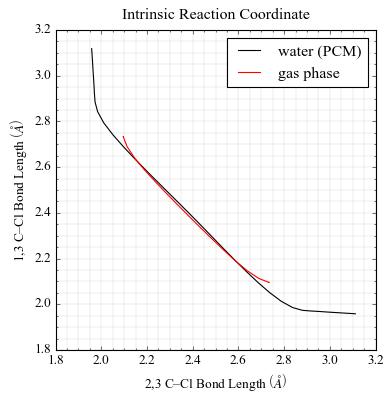

In [4]:
#| label: fig-irc-bonds
#| caption: The IRC expressed as a plot of distances to nucleophile and leaving group. Black is the solvent IRC and red is the gas phase IRC.
plt.style.use(DATA / "S2_classic2.mplstyle")
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(6, 5))

ax.plot(solvent["C-Cl2"], solvent["C-Cl1"], "k-", label="water (PCM)")
ax.plot(gasphase["C-Cl2"], gasphase["C-Cl1"], "r-", label="gas phase")

ax.set(title="Intrinsic Reaction Coordinate",
       ylabel=r"1,3 C–Cl Bond Length $\left(\AA\right)$",
       xlabel=r"2,3 C–Cl Bond Length $\left(\AA\right)$",
       aspect="equal")
ax.legend()

#fig.savefig("plot2.pdf")
plt.show()

The black line is the **solvent** IRC. What would you call that? I vote for "double ended hockey stick". It is clear that, at the beginning, **most** of the stride score is due to the nucleophile **moving in** towards the carbon. Only when it has come in a good part of the way do we see the leaving group **start to move** in concert. Read off your own plot: at what distance does the nucleophile **start** to push the leaving group away? Would you say that the reaction "begins" at that point? Does it end when the leaving group reaches that distance on the **other side**? Or should we include the translation of the nucleophile in from farther away?

The **gas phase** IRC is shorter because of the high cost of moving the chloride away in a vacuum. The key takeaway here is that solvent modeling has a **very large effect** in charged systems and probably a significant effect in every system.

Should we **redo everything** that we did up until now by adding a `$PCM` group to all our input files and running them again? That will be left as an exercise for the reader.

## Exploring the 3rd Dimension
Below is a 3D plot. I am just trying this out. I found some [instructions](https://jakevdp.github.io/PythonDataScienceHandbook/04.12-three-dimensional-plotting.html) in another useful online book. I also found information [here](https://matplotlib.org/stable/tutorials/toolkits/mplot3d.html) and [here](https://pythonprogramming.net/3d-graphs-matplotlib-tutorial/).

The grey lines are the **shadows** of the black curve on the three back walls of the box. The floor shows the bond-length plot from above, and the two walls show the energy against each bond length. The limits of the box are taken from the data, so the code works for the gas phase table too: change `solvent` to `gasphase` in the first line and run the cell again.

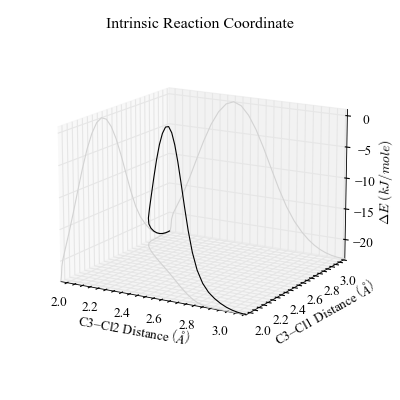

In [5]:
#| label: fig-irc-3d
#| caption: The IRC for the reaction in solvent.
irc = solvent                      # try gasphase here too

xline = irc["C-Cl2"]
yline = irc["C-Cl1"]
zline = irc["E(kJ/mole)"]
xlim = (xline.min(), xline.max())
ylim = (yline.min(), yline.max())
zlim = (zline.min(), zline.max() + 1)

fig = plt.figure(figsize=(7, 6))
ax = plt.axes(projection="3d")
ax.view_init(15, -60)

ax.plot(xline, yline, zs=zlim[0], zdir="z", color="lightgray")   # floor
ax.plot(yline, zline, zs=xlim[0], zdir="x", color="lightgray")   # left wall
ax.plot(xline, zline, zs=ylim[1], zdir="y", color="lightgray")   # back wall
ax.plot3D(xline, yline, zline, "k")

ax.set_xlabel(r"C3–Cl2 Distance $\left( \AA \right)$")
ax.set_ylabel(r"C3–Cl1 Distance $\left( \AA \right)$")
ax.set_zlabel(r"$\Delta E \  \left(kJ/mole\right)$")
ax.set_title("Intrinsic Reaction Coordinate")
ax.set_xlim(*xlim)
ax.set_ylim(*ylim)
ax.set_zlim(*zlim)
ax.set_box_aspect(None, zoom=0.85)   # shrink the box a little so the labels fit

#fig.savefig("plot3.pdf")
plt.show()

## AI Statement

This notebook is a revision of the original `10_Solvent_IRC_Plots-Data.ipynb`, made with the help of Claude (Anthropic) following the author's instructions.

- **Original text and code kept (about 85 %).** The explanations, the choice of the three plots and the plotting code are the author's.
- **Changed by AI.** The data are read from the book's own `data/` folder instead of a GitHub URL. The tables are now produced from your own *GAMESS* runs by the previous notebook (in the original, the gas-phase table was accidentally a copy of the solvent table, so the two curves lay on top of each other). Fixed axis limits were removed or computed from the data, legends were added, the x and y labels of the bond-length plot now match the columns plotted, and a sentence that quoted specific distances was turned into a question so that it stays true for your own numbers. The 3D plot gained a short explanation of its grey shadow lines. Figure labels were added so that the main chapter page can embed these plots.